In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt 
import seaborn as sns 
from  sklearn.datasets import load_iris



In [2]:
iris=load_iris()


X=pd.DataFrame(iris.data, columns=iris.feature_names)

X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
X.tail()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3
149,5.9,3.0,5.1,1.8


In [4]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [5]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


In [6]:
X.shape

(150, 4)

In [7]:
X.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

In [9]:
X.duplicated().sum()

np.int64(1)

In [10]:
X.drop_duplicates(inplace=True)

In [11]:
X.shape

(149, 4)

In [12]:
from sklearn.preprocessing import StandardScaler

In [13]:
Scale=StandardScaler()


X_scaled=Scale.fit_transform(X)

X_scaled

array([[-0.8980334 ,  1.01240113, -1.33325507, -1.30862368],
       [-1.13956224, -0.1373532 , -1.33325507, -1.30862368],
       [-1.38109108,  0.32254853, -1.39001364, -1.30862368],
       [-1.5018555 ,  0.09259766, -1.2764965 , -1.30862368],
       [-1.01879782,  1.242352  , -1.33325507, -1.30862368],
       [-0.53574014,  1.9322046 , -1.16297935, -1.04548613],
       [-1.5018555 ,  0.78245027, -1.33325507, -1.17705491],
       [-1.01879782,  0.78245027, -1.2764965 , -1.30862368],
       [-1.74338434, -0.36730407, -1.33325507, -1.30862368],
       [-1.13956224,  0.09259766, -1.2764965 , -1.44019246],
       [-0.53574014,  1.47230287, -1.2764965 , -1.30862368],
       [-1.26032666,  0.78245027, -1.21973792, -1.30862368],
       [-1.26032666, -0.1373532 , -1.33325507, -1.44019246],
       [-1.86414876, -0.1373532 , -1.50353079, -1.44019246],
       [-0.05268246,  2.16215547, -1.44677222, -1.30862368],
       [-0.17344688,  3.08195894, -1.2764965 , -1.04548613],
       [-0.53574014,  1.

In [14]:
from sklearn.cluster import KMeans

In [15]:
# elbow method

wcss=[]

for i in range(1,11):
    kmeans=KMeans(n_clusters=i,
                  random_state=112,
                  n_init=10)

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

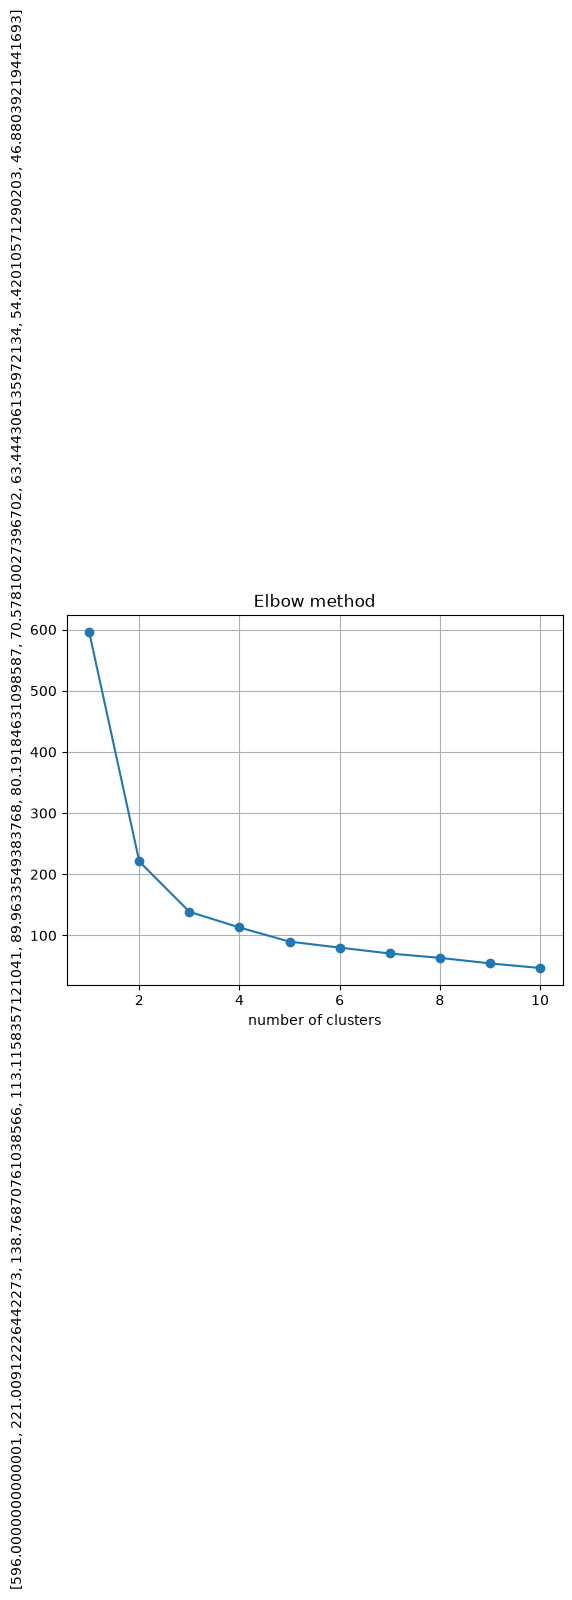

In [18]:
plt.Figure(figsize=(3,4))
plt.plot(range(1,11),wcss,marker="o")
plt.title("Elbow method")
plt.xlabel("number of clusters")
plt.ylabel(wcss)
plt.grid()
plt.show()

In [19]:
# apply k-means

kmeans=KMeans(n_clusters=3,
              random_state=112,
              n_init=10)


cluster=kmeans.fit_predict(X_scaled)

In [21]:
X["Cluster"]=cluster


print(X.sample(10))

     sepal length (cm)  sepal width (cm)  ...  petal width (cm)  Cluster
93                 5.0               2.3  ...               1.0        0
121                5.6               2.8  ...               2.0        0
94                 5.6               2.7  ...               1.3        0
145                6.7               3.0  ...               2.3        2
58                 6.6               2.9  ...               1.3        0
75                 6.6               3.0  ...               1.4        2
61                 5.9               3.0  ...               1.5        0
32                 5.2               4.1  ...               0.1        1
4                  5.0               3.6  ...               0.2        1
22                 4.6               3.6  ...               0.2        1

[10 rows x 5 columns]


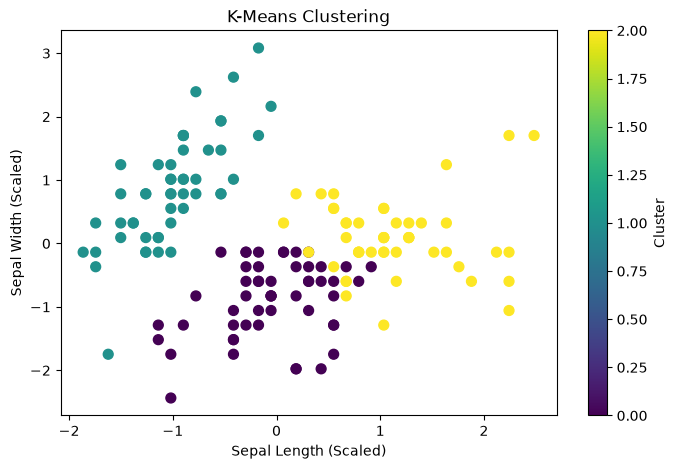

In [23]:
# Visualize K-Means Clusters

plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],   # First feature (Sepal Length)
    X_scaled[:, 1],   # Second feature (Sepal Width)
    c=cluster,        # Cluster labels
    cmap="viridis",
    s=50
)

plt.title("K-Means Clustering")
plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")

plt.colorbar(label="Cluster")
plt.show()

In [24]:
# evalut ion of cluster
from sklearn.metrics import silhouette_score

score=silhouette_score(X_scaled,cluster)

print("silhoueteescore",score)

silhoueteescore 0.46068122144785184


In [25]:
# cluster distribution

print(X["Cluster"].value_counts())

Cluster
0    52
1    50
2    47
Name: count, dtype: int64
